<a href="https://colab.research.google.com/github/yasintajeniarofina-oss/UTS-ML-2301010630-RofinaYasintaJenia/blob/main/UTS_ML_2301010630_Rofina_Yasinta_Jenia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility: 3 digit terakhir NIM 2301010630
SEED = 630
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (8, 5)
sns.set_theme(style="whitegrid")

# Cari file CSV di lokasi umum Colab / Drive
candidate_paths = [
    "/content/drive/MyDrive/retail_sales_dataset.csv",
    "/content/drive/MyDrive/Colab Notebooks/retail_sales_dataset.csv",
    "data/retail_sales_dataset.csv",
    "/content/data/retail_sales_dataset.csv",
    "retail_sales_dataset.csv",
    "/content/retail_sales_dataset.csv",
]
csv_path = next((p for p in candidate_paths if os.path.exists(p)), None)

if csv_path is None:
    from google.colab import files
    print("File belum ditemukan otomatis. Silakan pilih file CSV:")
    uploaded = files.upload()
    csv_path = next(iter(uploaded.keys()))

df = pd.read_csv(csv_path)
print("Path digunakan:", csv_path)
print("Jumlah baris & kolom:", df.shape)
display(df.head())
display(df.info())

Path digunakan: /content/drive/MyDrive/retail_sales_dataset.csv
Jumlah baris & kolom: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


None

,count,mean,std,min,25%,50%,75%,max
Age,1000.0,41.392,13.681430,18.0,29.0,42.0,53.0,64.0
Quantity,1000.0,2.514,1.132734,1.0,1.0,3.0,4.0,4.0
Price per Unit,1000.0,179.890,189.681356,25.0,30.0,50.0,300.0,500.0
Total Amount,1000.0,456.000,559.997632,25.0,60.0,135.0,900.0,2000.0



Nilai unik Gender: ['Male' 'Female']
Nilai unik Product Category: ['Beauty' 'Clothing' 'Electronics']


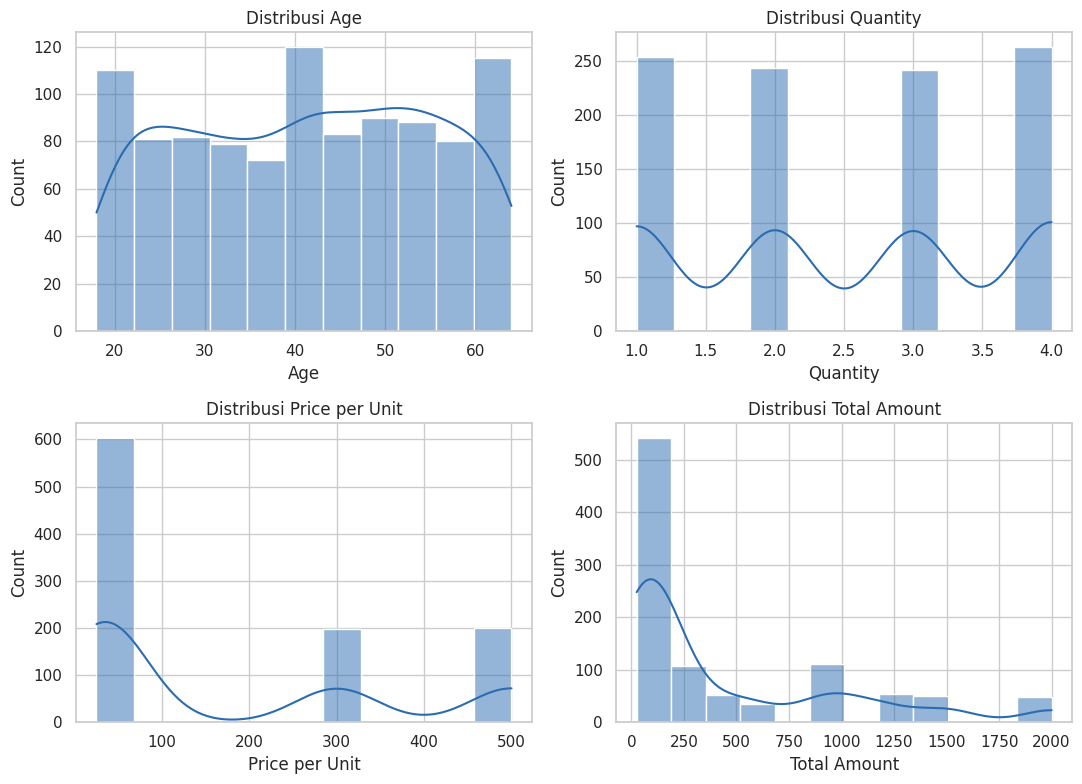

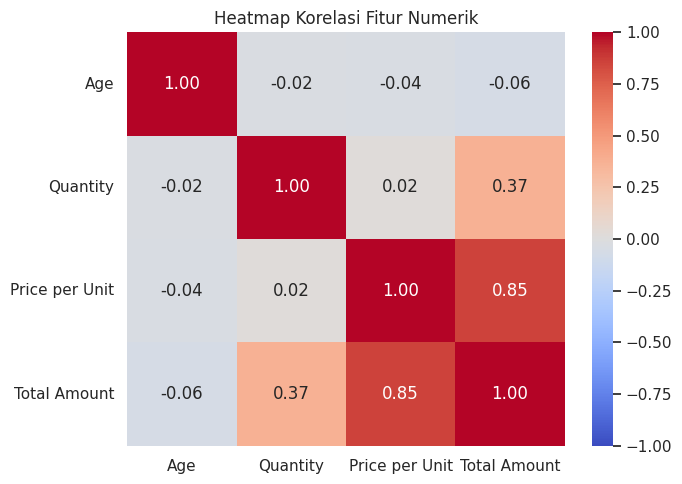

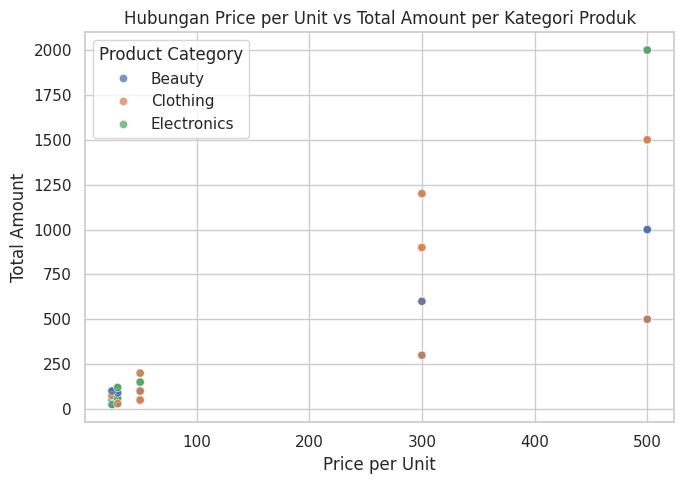

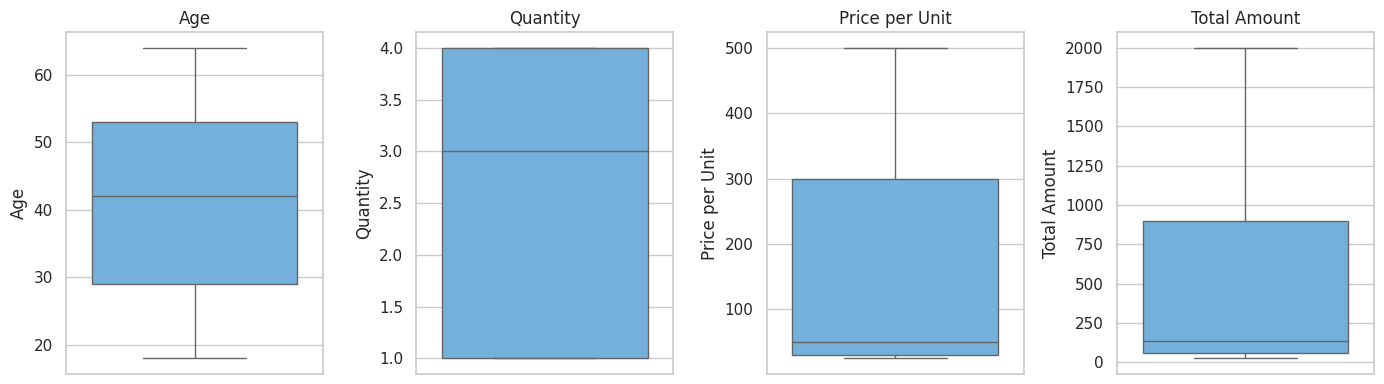

In [3]:
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
display(df[num_cols].describe().T)
print("\nNilai unik Gender:", df["Gender"].unique())
print("Nilai unik Product Category:", df["Product Category"].unique())

# 1. Distribusi Fitur Numerik
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#2b6cb0")
    ax.set_title(f"Distribusi {col}")
plt.tight_layout()
plt.show()

# 2. Hubungan Antar Fitur (Heatmap Korelasi & Scatter)
plt.figure(figsize=(7, 5))
corr = df[num_cols].corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Heatmap Korelasi Fitur Numerik")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Price per Unit", y="Total Amount", hue="Product Category", alpha=0.75)
plt.title("Hubungan Price per Unit vs Total Amount per Kategori Produk")
plt.tight_layout()
plt.show()

# 3. Boxplot untuk Melihat Outlier
fig, axes = plt.subplots(1, len(num_cols), figsize=(14, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="#63b3ed")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [4]:
from sklearn.preprocessing import StandardScaler

df_clean = df.copy()

# 1. Cek missing value & duplikat
print("Missing value per kolom:\n", df_clean.isnull().sum())
print("Jumlah baris duplikat penuh:", df_clean.duplicated().sum())
print("Jumlah duplikat Transaction ID:", df_clean["Transaction ID"].duplicated().sum())

# 2. Rapikan spasi & cek inkonsistensi kategori
for col in ["Gender", "Product Category"]:
    df_clean[col] = df_clean[col].astype(str).str.strip()
    print(f"Kategori unik {col}:", df_clean[col].value_counts().to_dict())

# 3. Pemeriksaan outlier menggunakan metode IQR pada fitur numerik clustering
cluster_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
outlier_summary = []
for col in cluster_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    outlier_summary.append({
        "Fitur": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "Batas Bawah": lower, "Batas Atas": upper, "Jumlah Outlier": n_out
    })
display(pd.DataFrame(outlier_summary))

# 4. Data sebelum scaling (tanpa scaling) & sesudah scaling (wajib untuk K-Means)
X_unscaled = df_clean[cluster_cols].copy()
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_unscaled),
    columns=cluster_cols,
    index=df_clean.index
)

print("\nRata-rata sebelum scaling:\n", X_unscaled.mean().round(2))
print("\nRata-rata & standar deviasi sesudah StandardScaler:")
display(X_scaled.agg(["mean", "std"]).round(4))

Missing value per kolom:
 Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64
Jumlah baris duplikat penuh: 0
Jumlah duplikat Transaction ID: 0
Kategori unik Gender: {'Female': 510, 'Male': 490}
Kategori unik Product Category: {'Clothing': 351, 'Electronics': 342, 'Beauty': 307}


,Fitur,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier
0,Age,29.0,53.0,24.0,-7.0,89.0,0
1,Quantity,1.0,4.0,3.0,-3.5,8.5,0
2,Price per Unit,30.0,300.0,270.0,-375.0,705.0,0
3,Total Amount,60.0,900.0,840.0,-1200.0,2160.0,0



Rata-rata sebelum scaling:
 Age                41.39
Quantity            2.51
Price per Unit    179.89
Total Amount      456.00
dtype: float64

Rata-rata & standar deviasi sesudah StandardScaler:


,Age,Quantity,Price per Unit,Total Amount
mean,-0.0000,0.0000,0.0000,-0.0000
std,1.0005,1.0005,1.0005,1.0005


,k,Inertia (Tanpa Scaling),Silhouette (Tanpa Scaling),Inertia (Dengan Scaling),Silhouette (Dengan Scaling)
0,2,7.593180e+07,0.7521,2413.7256,0.3917
1,3,3.163146e+07,0.7593,1848.3409,0.3355
2,4,1.525401e+07,0.7696,1455.9973,0.3575
3,5,9.067090e+06,0.7911,1179.4565,0.3530
4,6,6.405223e+06,0.8076,1001.5742,0.3745
5,7,4.247322e+06,0.7936,847.6887,0.3831
6,8,2.878767e+06,0.8313,715.1119,0.3966


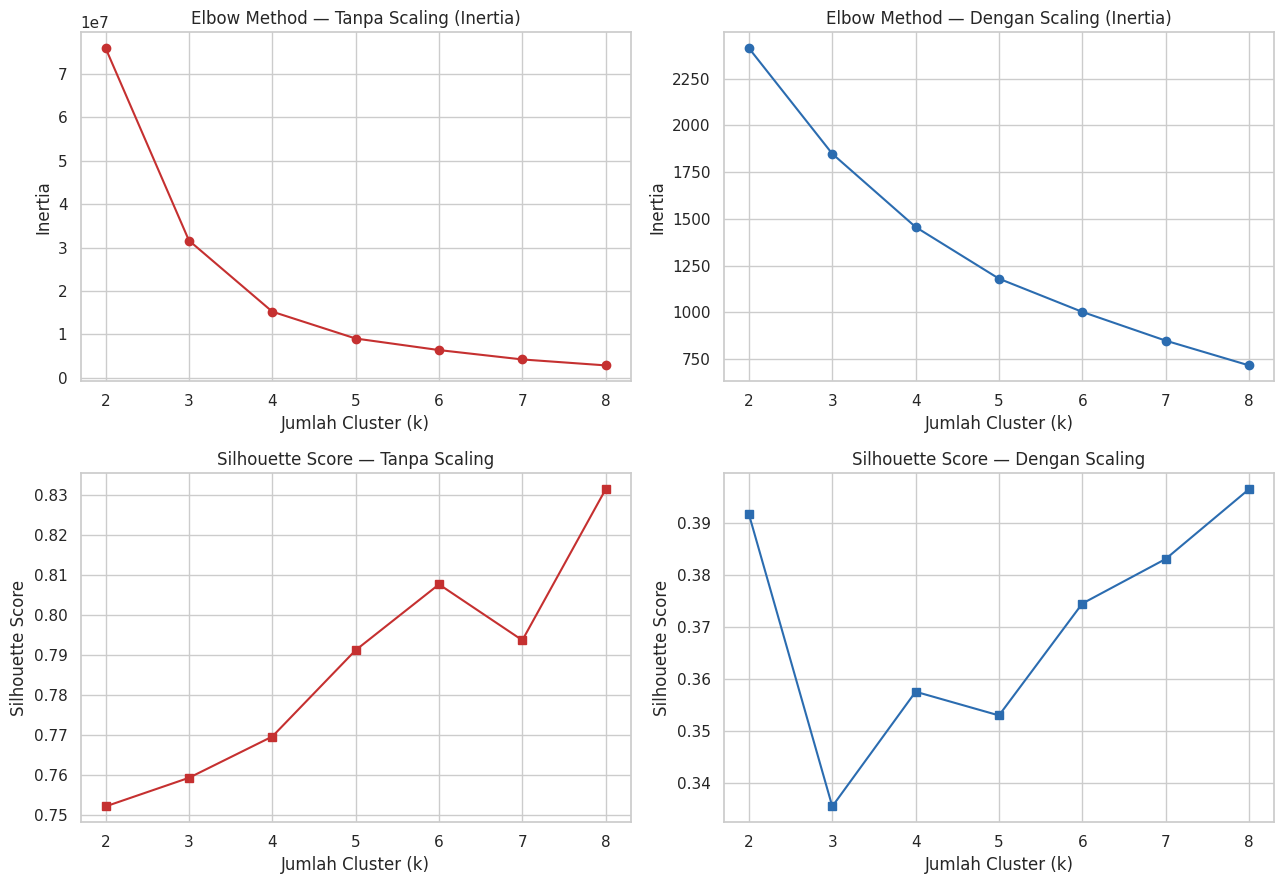

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Pastikan X_unscaled dan X_scaled sudah dibuat di Tahap 3
# (jika belum, jalankan dulu sel Tahap 3 sebelum sel ini)
k_values = range(2, 9)

def jalankan_kmeans_grid(X_data, k_range=k_values, seed=SEED):
    hasil = []
    model_map = {}
    label_map = {}
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=10, random_state=seed)
        labels = km.fit_predict(X_data)
        sil = silhouette_score(X_data, labels)
        hasil.append({
            "k": k,
            "inertia": km.inertia_,
            "silhouette": sil
        })
        model_map[k] = km
        label_map[k] = labels
    return pd.DataFrame(hasil), model_map, label_map

df_no_scale, models_no_scale, labels_no_scale = jalankan_kmeans_grid(X_unscaled, k_values, SEED)
df_scaled, models_scaled, labels_scaled = jalankan_kmeans_grid(X_scaled, k_values, SEED)

perbandingan_k = pd.merge(
    df_no_scale.rename(columns={"inertia": "Inertia (Tanpa Scaling)", "silhouette": "Silhouette (Tanpa Scaling)"}),
    df_scaled.rename(columns={"inertia": "Inertia (Dengan Scaling)", "silhouette": "Silhouette (Dengan Scaling)"}),
    on="k"
)
display(perbandingan_k.round(4))

# Grafik Perbandingan Elbow (Inertia) dan Silhouette: Tanpa vs Dengan Scaling
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Elbow Tanpa Scaling
axes[0, 0].plot(df_no_scale["k"], df_no_scale["inertia"], marker="o", color="#c53030")
axes[0, 0].set_title("Elbow Method — Tanpa Scaling (Inertia)")
axes[0, 0].set_xlabel("Jumlah Cluster (k)")
axes[0, 0].set_ylabel("Inertia")
axes[0, 0].set_xticks(list(k_values))

# 2. Elbow Dengan Scaling
axes[0, 1].plot(df_scaled["k"], df_scaled["inertia"], marker="o", color="#2b6cb0")
axes[0, 1].set_title("Elbow Method — Dengan Scaling (Inertia)")
axes[0, 1].set_xlabel("Jumlah Cluster (k)")
axes[0, 1].set_ylabel("Inertia")
axes[0, 1].set_xticks(list(k_values))

# 3. Silhouette Tanpa Scaling
axes[1, 0].plot(df_no_scale["k"], df_no_scale["silhouette"], marker="s", color="#c53030")
axes[1, 0].set_title("Silhouette Score — Tanpa Scaling")
axes[1, 0].set_xlabel("Jumlah Cluster (k)")
axes[1, 0].set_ylabel("Silhouette Score")
axes[1, 0].set_xticks(list(k_values))

# 4. Silhouette Dengan Scaling
axes[1, 1].plot(df_scaled["k"], df_scaled["silhouette"], marker="s", color="#2b6cb0")
axes[1, 1].set_title("Silhouette Score — Dengan Scaling")
axes[1, 1].set_xlabel("Jumlah Cluster (k)")
axes[1, 1].set_ylabel("Silhouette Score")
axes[1, 1].set_xticks(list(k_values))

plt.tight_layout()
plt.show()

=== Ukuran Cluster (K-Means Scaled, k=4, SEED=630) ===


,Jumlah Transaksi,Proporsi (%)
Cluster,,
0,215,21.5
1,289,28.9
2,181,18.1
3,315,31.5



=== Rata-rata Fitur Numerik per Cluster (Skala Asli) ===


,Age,Quantity,Price per Unit,Total Amount
Cluster,,,,
0,39.53,3.48,392.09,1365.58
1,41.75,3.55,35.50,126.45
2,42.09,1.46,410.50,603.87
3,41.93,1.50,35.02,52.56



=== Proporsi Product Category per Cluster (%) ===


Product Category,Beauty,Clothing,Electronics
Cluster,,,
0,30.70,34.88,34.42
1,31.83,37.37,30.80
2,30.39,33.70,35.91
3,29.84,33.97,36.19



=== Proporsi Gender per Cluster (%) ===


Gender,Female,Male
Cluster,,
0,51.16,48.84
1,53.63,46.37
2,52.49,47.51
3,47.62,52.38


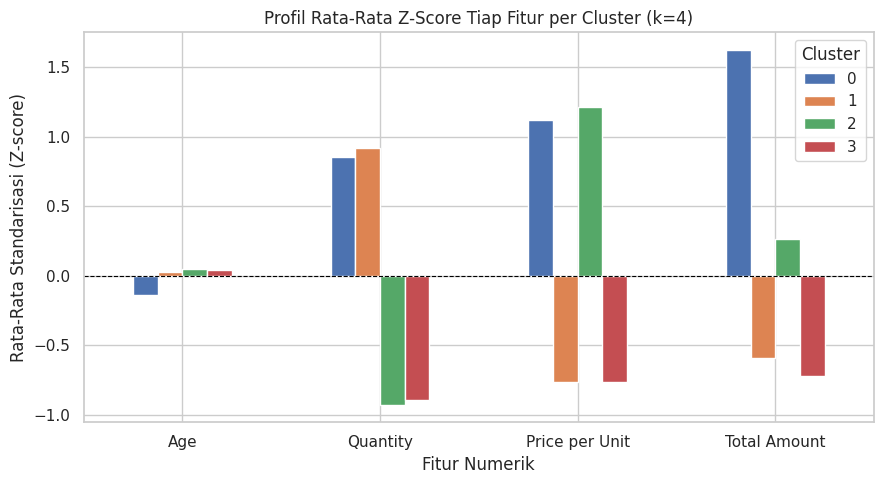

In [6]:
BEST_K = 4
best_labels = labels_scaled[BEST_K]

df_eval = df_clean.copy()
df_eval["Cluster"] = best_labels

# 1. Ukuran & proporsi tiap cluster
cluster_counts = df_eval["Cluster"].value_counts().sort_index()
cluster_summary_size = pd.DataFrame({
    "Jumlah Transaksi": cluster_counts,
    "Proporsi (%)": (cluster_counts / len(df_eval) * 100).round(2)
})
print(f"=== Ukuran Cluster (K-Means Scaled, k={BEST_K}, SEED={SEED}) ===")
display(cluster_summary_size)

# 2. Profil rata-rata fitur numerik (dalam skala asli agar mudah dibaca)
print("\n=== Rata-rata Fitur Numerik per Cluster (Skala Asli) ===")
display(df_eval.groupby("Cluster")[cluster_cols].mean().round(2))

# 3. Distribusi kategori per cluster
print("\n=== Proporsi Product Category per Cluster (%) ===")
display((pd.crosstab(df_eval["Cluster"], df_eval["Product Category"], normalize="index") * 100).round(2))

print("\n=== Proporsi Gender per Cluster (%) ===")
display((pd.crosstab(df_eval["Cluster"], df_eval["Gender"], normalize="index") * 100).round(2))

# 4. Visualisasi profil cluster (Pairplot / Barplot rata-rata fitur ter-scaling)
scaled_with_cluster = X_scaled.copy()
scaled_with_cluster["Cluster"] = best_labels
profile_z = scaled_with_cluster.groupby("Cluster").mean().T

profile_z.plot(kind="bar", figsize=(9, 5))
plt.title(f"Profil Rata-Rata Z-Score Tiap Fitur per Cluster (k={BEST_K})")
plt.ylabel("Rata-Rata Standarisasi (Z-score)")
plt.xlabel("Fitur Numerik")
plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.xticks(rotation=0)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

### Ringkasan & Interpretasi Cluster (K-Means Scaled, k = 4, SEED = 630)
Model membagi 1.000 transaksi menjadi 4 segmen utama berdasarkan kombinasi jumlah unit (`Quantity`), harga satuan (`Price per Unit`), dan nilai transaksi (`Total Amount`), sementara rata-rata `Age` berada di kisaran ~39,5 sampai 42,1 tahun serta proporsi `Product Category` dan `Gender` relatif merata antar cluster:
* **Cluster 0 (21,5% / 215 transaksi)**: Nilai transaksi tertinggi (rata-rata `Total Amount` = 1.365,58) akibat kombinasi `Quantity` tinggi (3,48) dan `Price per Unit` tinggi (392,09).
* **Cluster 1 (28,9% / 289 transaksi)**: Pembelian bervolume unit tinggi (3,55) dengan harga satuan rendah (35,50), menghasilkan `Total Amount` rata-rata 126,45.
* **Cluster 2 (18,1% / 181 transaksi)**: Pembelian berjumlah unit sedikit (1,46) namun bernilai satuan tinggi (410,50), sehingga `Total Amount` berada di tingkat menengah-tinggi (603,87).
* **Cluster 3 (31,5% / 315 transaksi)**: Segmen terbesar dengan `Quantity` sedikit (1,50) dan `Price per Unit` rendah (35,02), menghasilkan `Total Amount` terendah (52,56).

### Kelebihan, Keterbatasan, dan Catatan Risiko
* **Kelebihan**: `StandardScaler` mencegah `Total Amount` dan `Price per Unit` mendominasi jarak secara sepihak, sehingga pola volume (`Quantity`) vs nilai satuan (`Price per Unit`) terbaca jelas di 4 segmen.
* **Keterbatasan & Risiko**: Clustering dilakukan tanpa label ground-truth dan tanpa train-test split, nilai Silhouette (~0,33 sampai 0,40 pada data ter-scaling) menunjukkan batas antar cluster bersifat kontinu, serta fitur kategorikal (`Product Category`, `Gender`) dan tanggal (`Date`) tidak masuk langsung ke perhitungan jarak K-Means sehingga perlu kehati-hatian jika dipakai mengambil keputusan bisnis.

### Keputusan saya
> Saya menginterpretasikan empat cluster hasil K-Means ter-scaling (`k = 4`, `SEED = 630`) berdasarkan pola jumlah unit, harga satuan, dan total belanja, sambil mencatat keterbatasan clustering tanpa label dan tumpang tindih batas cluster. Langkah ini dipilih agar hasil segmentasi dipahami secara proporsional dan tidak ditafsirkan sebagai kelompok pelanggan yang terpisah kaku.

## Tahap 6. Kesimpulan

* **Ringkasan Temuan Utama**: Pada `retail_sales_dataset.csv` (1.000 transaksi, 9 kolom, tanpa label target), model K-Means dengan `StandardScaler` (`SEED = 630`) menghasilkan struktur cluster yang lebih seimbang antar fitur dibandingkan model tanpa scaling yang didominasi oleh besaran `Total Amount` dan `Price per Unit`. Pada `k = 4`, setiap cluster memperlihatkan kombinasi karakteristik usia pembeli, jumlah unit (`Quantity`), harga satuan, dan total nilai transaksi yang berbeda.
* **Pembelajaran Penting**: Pada algoritma berbasis jarak seperti K-Means, standarisasi fitur sangat menentukan arah pembentukan cluster, sementara nilai Silhouette (~0,33 sampai 0,40 pada data ter-scaling) menunjukkan bahwa data transaksi ritel bersifat kontinu dan tumpang tindih antar segmen, bukan terpisah kaku. Selain itu, karena ini clustering tanpa label dan tanpa train-test split, hasil cluster perlu dibaca sebagai pengelompokan pola deskriptif, bukan kebenaran mutlak.
* **Saran Tindak Lanjut**: Langkah berikutnya dapat menguji variasi `k` (misalnya `k = 2` atau `k = 6`), menyertakan fitur waktu transaksi (`Date`) atau kategori produk secara terpisah dengan perlakuan yang tepat, serta memvalidasi kegunaan segmen cluster bersama kebutuhan strategi promosi atau pengelolaan stok ritel.

### Keputusan saya
> Saya menutup analisis CRISP-DM Jalur C dengan merangkum perbedaan hasil tanpa vs dengan scaling, keterbatasan clustering tanpa label, dan arah tindak lanjut pada data ritel. Langkah ini dipilih agar kesimpulan tetap objektif sesuai bukti numerik serta siap digunakan sebagai bahan evaluasi dan pengembangan analisis lanjutan.